In [37]:

import os
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile, UnidentifiedImageError

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers




In [38]:

from pathlib import Path


DATASET_DIR = Path("../data/chest_xray")

if DATASET_DIR.exists():
    print("Dataset folder found!")
else:
    print("Error: Dataset folder not found.")
    print("Please check the folder path.")

images = ["test","train", "val"]
images_directories = []
for images_name in images : 
    images_dir = DATASET_DIR / images_name
    if images_dir.is_dir():
        print(f"{images_name} folder found!")
        images_directories.append(images_dir)   
    else:
        print(f"Error: {images_name} folder not found!")


CLASSES = ["NORMAL", "PNEUMONIA"]


for img_dic in images_directories:
    for class_name in CLASSES:
        class_dir = img_dic / class_name
        if class_dir.is_dir():
            print(f"{class_name} folder found!")
        else:
            print(f"Error: {class_name} folder not found!")

print("\nDataset location:", DATASET_DIR.resolve())
print("Classes:", CLASSES)
print(images_directories)


Dataset folder found!
test folder found!
train folder found!
val folder found!
NORMAL folder found!
PNEUMONIA folder found!
NORMAL folder found!
PNEUMONIA folder found!
NORMAL folder found!
PNEUMONIA folder found!

Dataset location: C:\Users\laaou\OneDrive\Desktop\projects\PneumoVision AI\data\chest_xray
Classes: ['NORMAL', 'PNEUMONIA']
[WindowsPath('../data/chest_xray/test'), WindowsPath('../data/chest_xray/train'), WindowsPath('../data/chest_xray/val')]


In [39]:


for images_dir in images_directories:
    print(f"\n{images_dir.name.upper()} DATASET")

    for class_name in CLASSES:
        class_dir = images_dir / class_name

        image_files = [
            file for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{class_name}: {len(image_files)} images")



TEST DATASET
NORMAL: 234 images
PNEUMONIA: 390 images

TRAIN DATASET
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL DATASET
NORMAL: 8 images
PNEUMONIA: 8 images


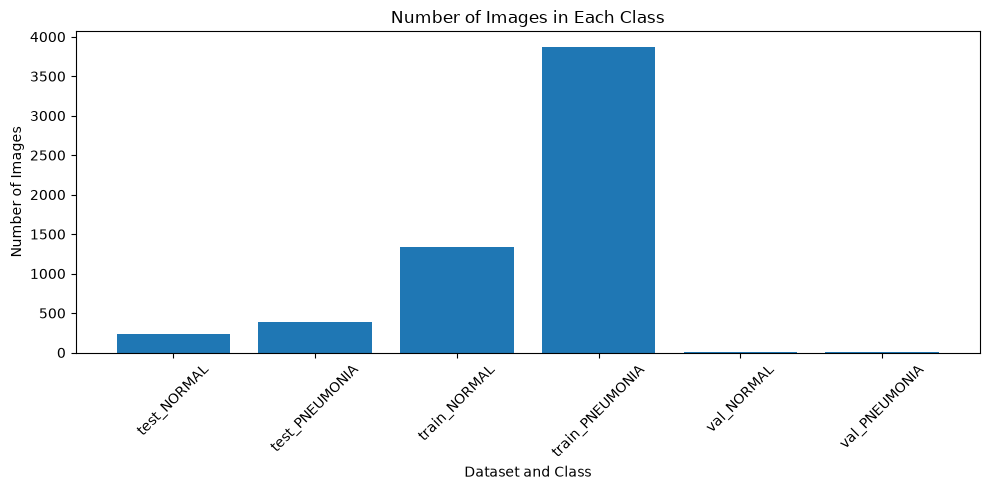

In [40]:

import matplotlib.pyplot as plt

class_counts = {}

for images_dir in images_directories:
    for class_name in CLASSES:

        class_dir = images_dir / class_name

        image_files = [
            file for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        class_counts[f"{images_dir.name}_{class_name}"] = len(image_files)

plt.figure(figsize=(10, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Number of Images in Each Class")
plt.xlabel("Dataset and Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


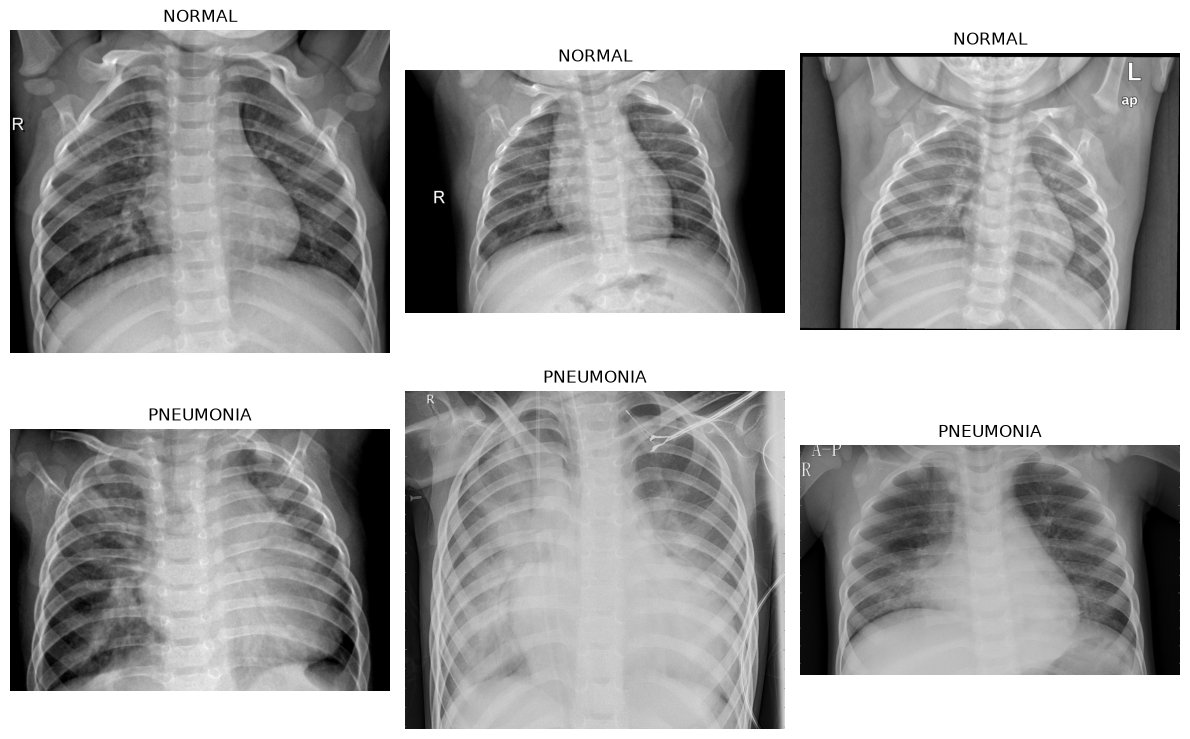

In [41]:

from PIL import Image
import random
import matplotlib.pyplot as plt

train_folder = DATASET_DIR / "train"

plt.figure(figsize=(12, 8))

for class_name in CLASSES:

    class_folder = train_folder / class_name

    image_files = list(class_folder.glob("*.jpeg"))
    image_files += list(class_folder.glob("*.jpg"))
    image_files += list(class_folder.glob("*.png"))

    samples = random.sample(image_files, min(3, len(image_files)))

    for image_path in samples:

        image = Image.open(image_path)

        plt.subplot(2, 3, len(plt.gcf().axes) + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


Original size: (2090, 1858)
Original format: L
New size: (180, 180)
New format: RGB


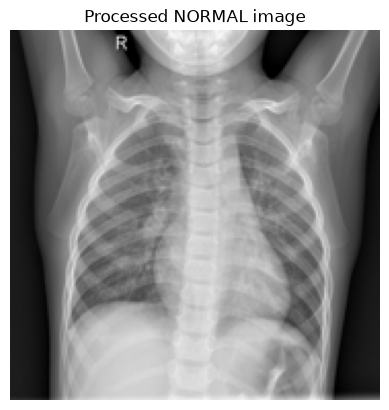

In [42]:

from PIL import Image
import matplotlib.pyplot as plt

normal_folder = DATASET_DIR / "train" / "NORMAL"

image_files = list(normal_folder.glob("*.jpeg"))
image_files += list(normal_folder.glob("*.jpg"))
image_files += list(normal_folder.glob("*.png"))

image_path = image_files[0]

image = Image.open(image_path)

print("Original size:", image.size)
print("Original format:", image.mode)

image = image.resize((180, 180))

image = image.convert("RGB")

print("New size:", image.size)
print("New format:", image.mode)

plt.imshow(image)
plt.title("Processed NORMAL image")
plt.axis("off")
plt.show()


In [43]:

import numpy as np
from PIL import Image

def load_split(split_name):
    folder = DATASET_DIR / split_name
    X = []
    y = []

    for class_name in CLASSES:
        class_folder = folder / class_name

        image_files = list(class_folder.glob("*.jpeg"))
        image_files += list(class_folder.glob("*.jpg"))
        image_files += list(class_folder.glob("*.png"))

        if class_name == "NORMAL":
            label = 0
        else:
            label = 1

        for image_path in image_files:
            image = Image.open(image_path)
            image = image.convert("RGB")
            image = image.resize((180, 180))
            image_array = np.array(image)

            X.append(image_array)    
            y.append(label)

    
    return np.array(X), np.array(y)
    




X_train, y_train = load_split("train")
X_val,   y_val   = load_split("val")
X_test,  y_test  = load_split("test")

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)



Train: (5216, 180, 180, 3) (5216,)
Val:   (16, 180, 180, 3) (16,)
Test:  (624, 180, 180, 3) (624,)


In [44]:
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())     # 0.0 and 1.0

0.0 1.0


In [45]:
print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape, y_val.shape)
print("Test  :", X_test.shape, y_test.shape)

print("Pixel minimum :", X_train.min())
print("Pixel maximum :", X_train.max())

print("Labels :", np.unique(y_train))

Train : (5216, 180, 180, 3) (5216,)
Val   : (16, 180, 180, 3) (16,)
Test  : (624, 180, 180, 3) (624,)
Pixel minimum : 0.0
Pixel maximum : 1.0
Labels : [0 1]


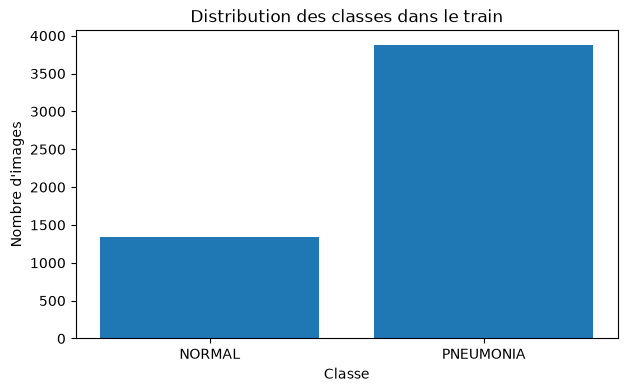

In [46]:
import matplotlib.pyplot as plt

class_names = ["NORMAL", "PNEUMONIA"]

counts = [
    np.sum(y_train == 0),
    np.sum(y_train == 1)
]

plt.figure(figsize=(7, 4))
plt.bar(class_names, counts)
plt.title("Distribution des classes dans le train")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()

In [47]:
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [48]:
from tensorflow.keras import layers, models
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [49]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [50]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_1               │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [51]:
EPOCHS = 20
BATCH_SIZE = 32

In [52]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 60s 356ms/step - accuracy: 0.8232 - loss: 0.4211 - precision: 0.8310 - recall: 0.9566 - val_accuracy: 0.7500 - val_loss: 0.5791 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 362ms/step - accuracy: 0.9018 - loss: 0.2354 - precision: 0.9226 - recall: 0.9474 - val_accuracy: 0.8125 - val_loss: 0.3800 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 361ms/step - accuracy: 0.9229 - loss: 0.1984 - precision: 0.9404 - recall: 0.9569 - val_accuracy: 0.6250 - val_loss: 0.9770 - val_precision: 0.5714 - val_recall: 1.0000
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 58s 359ms/step - accuracy: 0.9298 - loss: 0.1766 - precision: 0.9484 - recall: 0.9577 - val_accuracy: 0.7500 - val_loss: 0.6265 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 364ms/step - accuracy: 0.9402 - loss: 0.1525 - precision: 0.9569 - recall: 0.9628 - val_accuracy: 0.7500

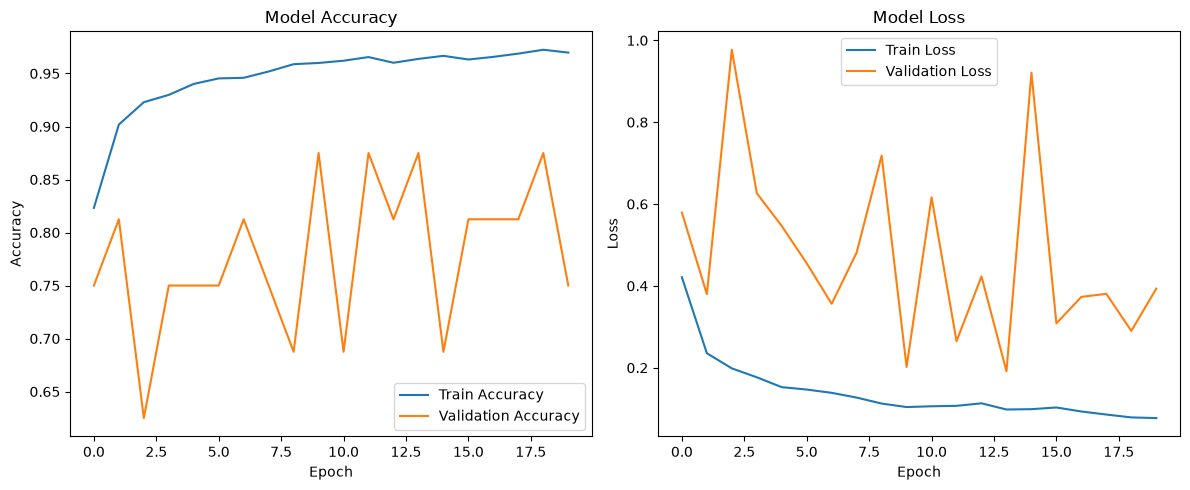

In [53]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [54]:
best_accuracy = max(history.history["val_accuracy"])
best_loss = min(history.history["val_loss"])

print(f"Best validation accuracy: {best_accuracy:.4f}")
print(f"Best validation loss: {best_loss:.4f}")

Best validation accuracy: 0.8750
Best validation loss: 0.1913


In [55]:
import tensorflow as tf
import time

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

In [56]:
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")
print(f"Epochs completed: {len(history.history['loss'])}")

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 56s 346ms/step - accuracy: 0.9716 - loss: 0.0806 - precision: 0.9789 - recall: 0.9830 - val_accuracy: 0.8125 - val_loss: 0.4339 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 347ms/step - accuracy: 0.9745 - loss: 0.0728 - precision: 0.9817 - recall: 0.9840 - val_accuracy: 0.7500 - val_loss: 0.3886 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 347ms/step - accuracy: 0.9751 - loss: 0.0753 - precision: 0.9840 - recall: 0.9825 - val_accuracy: 0.8125 - val_loss: 0.3252 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 348ms/step - accuracy: 0.9753 - loss: 0.0723 - precision: 0.9847 - recall: 0.9819 - val_accuracy: 0.6875 - val_loss: 0.7579 - val_precision: 0.6154 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 58s 356ms/st

In [57]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_prob = model.predict(X_test).ravel()

y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step
Accuracy:  0.7452
Precision: 0.7112
Recall:    0.9974
F1-score:  0.8303
ROC-AUC:   0.9372


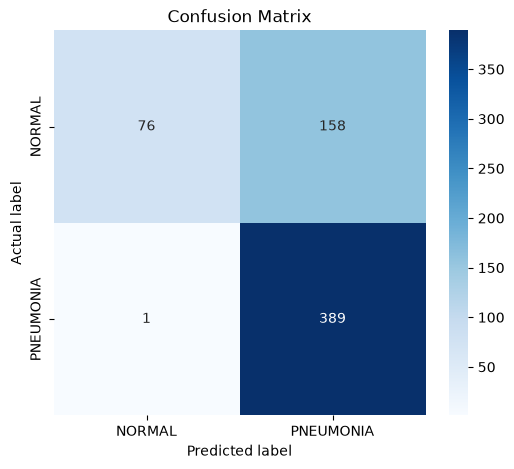

              precision    recall  f1-score   support

      NORMAL       0.99      0.32      0.49       234
   PNEUMONIA       0.71      1.00      0.83       390

    accuracy                           0.75       624
   macro avg       0.85      0.66      0.66       624
weighted avg       0.81      0.75      0.70       624



In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

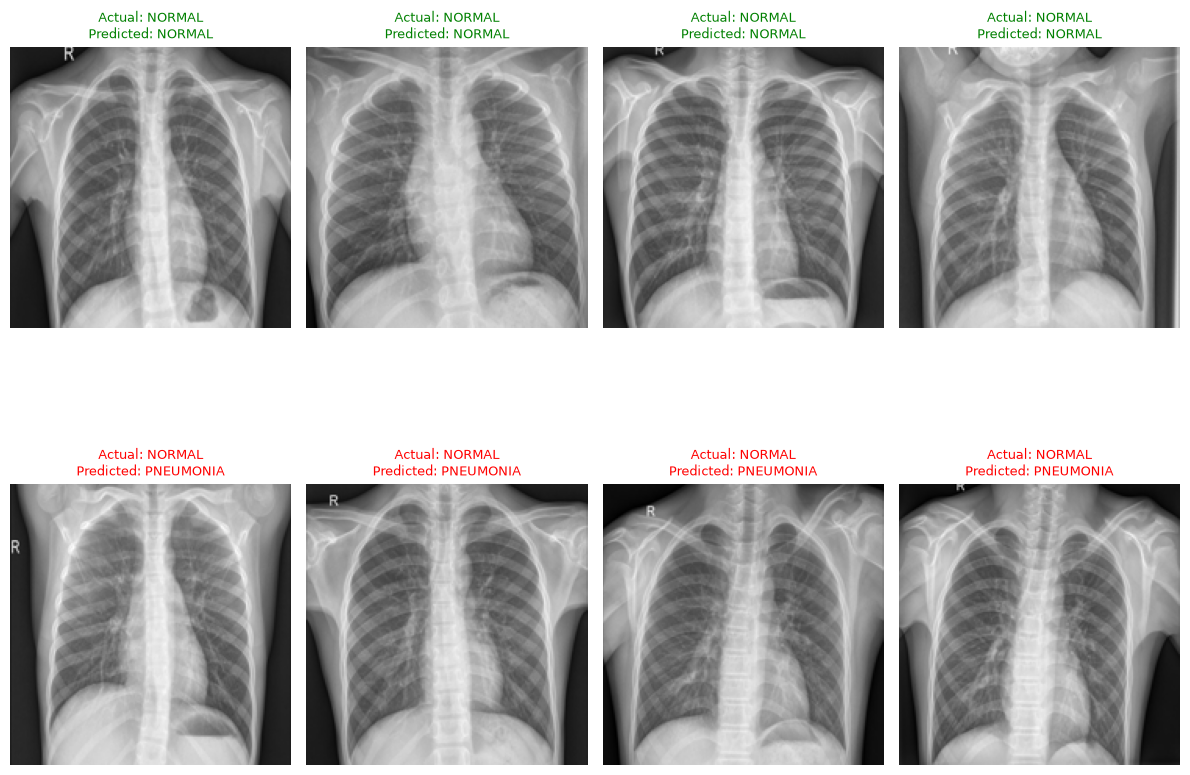

In [59]:
import matplotlib.pyplot as plt
import numpy as np

correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

selected_correct = correct_indices[:4]
selected_incorrect = incorrect_indices[:4]

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

plt.figure(figsize=(12, 10))

for i, idx in enumerate(selected_indices):
    plt.subplot(2, 4, i + 1)

    plt.imshow(X_test[idx])

    actual_label = "PNEUMONIA" if y_test[idx] == 1 else "NORMAL"
    predicted_label = "PNEUMONIA" if y_pred[idx] == 1 else "NORMAL"

    color = "green" if y_pred[idx] == y_test[idx] else "red"

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [60]:
from sklearn.metrics import accuracy_score

train_pred = (model.predict(X_train, verbose=0).ravel() >= 0.5).astype(int)
val_pred = (model.predict(X_val, verbose=0).ravel() >= 0.5).astype(int)
test_pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)

train_accuracy = accuracy_score(y_train, train_pred)
val_accuracy = accuracy_score(y_val, val_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Training Accuracy:   {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Test Accuracy:       {test_accuracy:.4f}")

Training Accuracy:   0.9864
Validation Accuracy: 0.8125
Test Accuracy:       0.7452
